# Binary_DINOv2_Baseline_V2: Binary Skin Lesion Classification (DINOv2 (ViT-B/14))

Baseline experiment for the Soft Voting Ensemble project. Consumes **only** the already-merged,
already-split, already-deduplicated outputs of `01_preprocessing.ipynb`
(`Data/datasets/HAM10000_ISICExtra_binary/`). No preprocessing, no re-splitting, no metadata
regeneration happens in this notebook.

**Labels:** 0 = Benign, 1 = Malignant.

**Backbone:** DINOv2 (ViT-B/14). The fine-tuning strategy (Section 9) is chosen specifically
for this architecture - it is deliberately **not** copied from the other baseline notebooks in
this project. Dataset, split, metrics, error analysis, output structure, logging, and the
`predictions.csv` contract are identical across all baselines so they remain directly comparable
and ensemble-compatible; only the model and its fine-tuning schedule differ.

**Output contract for the ensemble:** this notebook writes `predictions.csv` with columns
`image_id, true_label, predicted_label, probability_benign, probability_malignant`, verified and
explicitly sorted by `image_id` (never relying on row/iteration order) before saving.


## 1. Imports

In [1]:
import os
import json
import random
import logging
import warnings
from pathlib import Path
from datetime import datetime, timezone
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler
import torchvision
from torchvision import transforms
from torchvision.transforms import InterpolationMode

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, brier_score_loss,
)
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")


## 2. Reproducibility

In [2]:
RANDOM_STATE = 42

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed(RANDOM_STATE)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## 3. Logging

In [3]:
RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

logger = logging.getLogger("Binary_DINOv2_Baseline_V2")
logger.setLevel(logging.INFO)
logger.handlers.clear()
_formatter = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
_console_handler = logging.StreamHandler()
_console_handler.setFormatter(_formatter)
logger.addHandler(_console_handler)


## 4. Configuration

Paths and the hyperparameters common to every baseline notebook. Backbone-specific values
(`img_size`, `norm_mean/std`, learning rates, freeze schedule) are set here as defaults and then
**overridden with the backbone's own official values** once the model is built (Section 9) -
e.g. DINOv2's exact expected input size/normalization comes from `timm`, EfficientNet-B3's from
its official torchvision transform metadata, not from a value guessed here.

**Output directory structure** is identical across all three V2 baselines (and the DenseNet121
V2 notebook), so the project has one consistent layout regardless of backbone:
```
outputs/binary/<Name>_V2/
  checkpoints/best_model.pth
  predictions/predictions.csv, val_predictions.csv
  plots/
    training_curves/loss_curve.png, accuracy_curve.png, auc_curve.png
    roc_pr_curves/roc_curve.png, precision_recall_curve.png
    confusion_matrices/confusion_matrix.png, normalized_confusion_matrix.png
    calibration/reliability_diagram.png, calibration_curve.png
    error_analysis/{false_positive,false_negative,true_positive,true_negative}_grid.png
  error_analysis/{TP,TN,FP,FN}.csv, error_analysis_stats.json
  classification_report_f1_optimal.json
  metrics_summary.json
  run_config.json
  training_history.csv
```

In [4]:
def find_project_root(start: Path, markers=("Data", "notebooks")) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if all((candidate / marker).exists() for marker in markers):
            return candidate
    raise FileNotFoundError(f"Could not find a project root containing {markers} above {start}.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_DIR = PROJECT_ROOT / "Data" / "datasets" / "HAM10000_ISICExtra_binary"
METADATA_DIR = DATASET_DIR / "metadata"
IMAGES_DIR = DATASET_DIR / "images"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "binary" / "Binary_DINOv2_Baseline_V2"
CHECKPOINTS_DIR = OUTPUT_DIR / "checkpoints"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
PLOTS_DIR = OUTPUT_DIR / "plots"
TRAINING_CURVES_DIR = PLOTS_DIR / "training_curves"
ROC_PR_DIR = PLOTS_DIR / "roc_pr_curves"
CONFUSION_MATRICES_DIR = PLOTS_DIR / "confusion_matrices"
CALIBRATION_DIR = PLOTS_DIR / "calibration"
PLOTS_ERROR_ANALYSIS_DIR = PLOTS_DIR / "error_analysis"
ERROR_ANALYSIS_DIR = OUTPUT_DIR / "error_analysis"  # CSVs + stats (plots for these live under PLOTS_ERROR_ANALYSIS_DIR)

for d in [OUTPUT_DIR, CHECKPOINTS_DIR, PREDICTIONS_DIR, TRAINING_CURVES_DIR, ROC_PR_DIR,
          CONFUSION_MATRICES_DIR, CALIBRATION_DIR, PLOTS_ERROR_ANALYSIS_DIR, ERROR_ANALYSIS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "batch_size": 32,
    "num_workers": 0,
    "epochs": 20,
    "early_stopping_patience": 5,
    "grad_clip_norm": 1.0,
    "use_amp": torch.cuda.is_available(),
    "cb_beta": 0.9999,     # Class-Balanced Loss (Cui et al. 2019) effective-number-of-samples beta
    "focal_gamma": 2.0,    # Focal Loss (Lin et al. 2017) focusing parameter
    "use_tta": True,       # 3-view test-time augmentation (identity, h-flip, v-flip) at inference
    # --- backbone-specific defaults (may be overridden with official values in Section 9) ----
    "img_size": 224,
    "backbone_lr": 2e-06,
    "head_lr": 0.001,
    "weight_decay": 0.05,
    "warmup_freeze_epochs": 3,
    "unfreeze_last_n_blocks": 1,
}

logger.info("PROJECT_ROOT: %s", PROJECT_ROOT)
logger.info("DATASET_DIR: %s", DATASET_DIR)
logger.info("OUTPUT_DIR: %s", OUTPUT_DIR)
logger.info("DEVICE: %s", DEVICE)
logger.info("CONFIG (pre-backbone-resolution): %s", CONFIG)


2026-07-22 18:15:26,218 | INFO | PROJECT_ROOT: D:\SkinCancer_Project
2026-07-22 18:15:26,218 | INFO | DATASET_DIR: D:\SkinCancer_Project\Data\datasets\HAM10000_ISICExtra_binary
2026-07-22 18:15:26,219 | INFO | OUTPUT_DIR: D:\SkinCancer_Project\outputs\binary\Binary_DINOv2_Baseline_V2
2026-07-22 18:15:26,220 | INFO | DEVICE: cuda
2026-07-22 18:15:26,220 | INFO | CONFIG (pre-backbone-resolution): {'batch_size': 32, 'num_workers': 0, 'epochs': 20, 'early_stopping_patience': 5, 'grad_clip_norm': 1.0, 'use_amp': True, 'cb_beta': 0.9999, 'focal_gamma': 2.0, 'use_tta': True, 'img_size': 224, 'backbone_lr': 2e-06, 'head_lr': 0.001, 'weight_decay': 0.05, 'warmup_freeze_epochs': 3, 'unfreeze_last_n_blocks': 1}


## 5. Dataset Validation

Confirms the preprocessing outputs exist and are well-formed before anything else runs.

In [5]:
REQUIRED_FILES = ["train.csv", "val.csv", "test.csv"]
REQUIRED_COLUMNS = {"image_id", "image_path"}
REQUIRED_IMAGE_SPLIT_DIRS = ["train", "val", "test"]


def verify_dataset(metadata_dir: Path, images_dir: Path) -> None:
    if not metadata_dir.exists():
        raise FileNotFoundError(f"Metadata directory not found: {metadata_dir}")
    missing = [f for f in REQUIRED_FILES if not (metadata_dir / f).exists()]
    if missing:
        raise FileNotFoundError(f"Missing expected file(s) in {metadata_dir}: {missing}")
    for filename in REQUIRED_FILES:
        cols = set(pd.read_csv(metadata_dir / filename, nrows=1).columns)
        missing_cols = REQUIRED_COLUMNS - cols
        if missing_cols:
            raise ValueError(f"{filename} is missing required column(s): {missing_cols}")
    missing_dirs = [d for d in REQUIRED_IMAGE_SPLIT_DIRS if not (images_dir / d).exists()]
    if missing_dirs:
        raise FileNotFoundError(f"Missing image split folder(s) in {images_dir}: {missing_dirs}")
    logger.info("Dataset structure verified: %s | %s", metadata_dir, images_dir)


verify_dataset(METADATA_DIR, IMAGES_DIR)


2026-07-22 18:15:26,237 | INFO | Dataset structure verified: D:\SkinCancer_Project\Data\datasets\HAM10000_ISICExtra_binary\metadata | D:\SkinCancer_Project\Data\datasets\HAM10000_ISICExtra_binary\images


## 6. Load Splits, Resolve Image Paths, Prepare Binary Labels

Loads the immutable train/val/test CSVs. `image_path` is inspected first - left untouched if it
already points at the processed, copied image for that split; only rebuilt (by filename) if it
still points somewhere else. `binary_label` is used directly if present; otherwise derived from
`dx`. Execution stops with a clear error if validation fails.

In [6]:
BINARY_LABEL_MAP = {"mel": 1, "bcc": 1, "akiec": 1, "nv": 0, "bkl": 0, "df": 0, "vasc": 0}
BINARY_LABEL_NAMES = {0: "Benign", 1: "Malignant"}


def load_split(metadata_dir: Path, filename: str) -> pd.DataFrame:
    df = pd.read_csv(metadata_dir / filename)
    logger.info("Loaded %s: %d rows", filename, len(df))
    return df


def resolve_processed_image_paths(df: pd.DataFrame, images_dir: Path, split_name: str) -> pd.DataFrame:
    df = df.copy()
    split_dir = images_dir / split_name

    def _resolve(raw_path: str) -> str:
        current_path = Path(raw_path)
        if current_path.parent == split_dir:
            return str(current_path)  # already correct - do not modify
        return str(split_dir / current_path.name)  # stale/raw - rebuild

    already_correct = (df["image_path"].apply(lambda p: Path(p).parent) == split_dir).sum()
    df["image_path"] = df["image_path"].apply(_resolve)
    logger.info("%s: image_path already correct for %d/%d row(s); rebuilt the rest",
                split_name, int(already_correct), len(df))
    return df


def prepare_binary_labels(df: pd.DataFrame, name: str) -> pd.DataFrame:
    df = df.copy()
    if "binary_label" not in df.columns:
        if "dx" not in df.columns:
            raise ValueError(f"{name}: neither binary_label nor dx present - cannot derive labels.")
        logger.warning("%s: binary_label missing, deriving from dx.", name)
        df["binary_label"] = df["dx"].map(BINARY_LABEL_MAP)

    n_missing = int(df["binary_label"].isna().sum())
    if n_missing > 0:
        raise ValueError(f"{name}: {n_missing} row(s) have missing/unmapped binary_label. Aborting.")
    observed_classes = set(df["binary_label"].unique().tolist())
    if observed_classes != {0, 1}:
        raise ValueError(f"{name}: expected exactly classes {{0,1}}, found {observed_classes}. Aborting.")
    df["binary_label"] = df["binary_label"].astype(int)
    logger.info("%s: %d rows, class counts %s", name, len(df), df["binary_label"].value_counts().to_dict())
    return df


train_df = prepare_binary_labels(resolve_processed_image_paths(load_split(METADATA_DIR, "train.csv"), IMAGES_DIR, "train"), "train")
val_df = prepare_binary_labels(resolve_processed_image_paths(load_split(METADATA_DIR, "val.csv"), IMAGES_DIR, "val"), "val")
test_df = prepare_binary_labels(resolve_processed_image_paths(load_split(METADATA_DIR, "test.csv"), IMAGES_DIR, "test"), "test")

# Cross-split leakage check on image_id before building any Dataset/DataLoader.
id_sets = {"train": set(train_df["image_id"]), "val": set(val_df["image_id"]), "test": set(test_df["image_id"])}
overlaps = {
    "train_val": id_sets["train"] & id_sets["val"],
    "train_test": id_sets["train"] & id_sets["test"],
    "val_test": id_sets["val"] & id_sets["test"],
}
total_overlap = sum(len(v) for v in overlaps.values())
if total_overlap > 0:
    raise RuntimeError(f"Data leakage detected across splits: { {k: len(v) for k, v in overlaps.items()} }. Aborting.")
logger.info("Leakage check passed: no overlapping image_id across train/val/test.")

if test_df["image_id"].duplicated().any():
    raise RuntimeError("test.csv contains duplicate image_id values - aborting before any inference.")


2026-07-22 18:15:26,267 | INFO | Loaded train.csv: 8587 rows
2026-07-22 18:15:26,359 | INFO | train: image_path already correct for 0/8587 row(s); rebuilt the rest
2026-07-22 18:15:26,359 | INFO | train: 8587 rows, class counts {0: 5897, 1: 2690}
2026-07-22 18:15:26,369 | INFO | Loaded val.csv: 2147 rows
2026-07-22 18:15:26,391 | INFO | val: image_path already correct for 0/2147 row(s); rebuilt the rest
2026-07-22 18:15:26,393 | INFO | val: 2147 rows, class counts {0: 1474, 1: 673}
2026-07-22 18:15:26,400 | INFO | Loaded test.csv: 2147 rows
2026-07-22 18:15:26,423 | INFO | test: image_path already correct for 0/2147 row(s); rebuilt the rest
2026-07-22 18:15:26,423 | INFO | test: 2147 rows, class counts {0: 1473, 1: 674}
2026-07-22 18:15:26,423 | INFO | Leakage check passed: no overlapping image_id across train/val/test.


## 7. Dataset Class

Built once here with placeholder transforms; the actual transform pipeline is finalized in
Section 10 once the backbone (Section 9) has resolved its exact expected preprocessing.

In [7]:
class SkinLesionDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform: transforms.Compose):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        image = self.transform(image)
        label = torch.tensor(row["binary_label"], dtype=torch.float32)
        return image, label, row["image_id"]


## 8. DataLoaders

Deferred until after Section 9, since the transform pipeline depends on the backbone's resolved
`img_size`/normalization/interpolation - building loaders here would risk using placeholder
values. See Section 10.

In [8]:
# Intentionally left for Section 10 (after the backbone resolves its own preprocessing).


## 9. Fine-Tuning Strategy: DINOv2 (ViT-B/14)

**Do not copy the DenseNet/CNN playbook here - DINOv2 needs a different strategy.**

DINOv2 is a *self-supervised* Vision Transformer (86M params for ViT-B/14). Three facts from
the official model card and published evaluations drive the choice below, not a generic
transfer-learning default:

1. **Meta's own guidance**: DINOv2 features are explicitly designed to work well with a simple
   linear/MLP classifier on top of *frozen* features - that is the primary recommended usage
   pattern, not full fine-tuning.
2. **Full fine-tuning measurably hurts DINOv2 on small/medium datasets.** A direct DINOv2-vs-
   supervised-backbone comparison (VTAB-1K, a low-data benchmark) found full fine-tuning
   "significantly worsens" with DINOv2 relative to linear probing, because the 86M-parameter
   backbone overfits before the classifier converges. Our dataset (~13k images, and some
   malignant subtypes with only ~100-300 samples) is exactly this low/medium-data regime.
3. **Partial "last-block" unfreezing recovers most of full fine-tuning's benefit at much lower
   risk.** A building-imagery study comparing linear probing / last-3-block / progressive /
   full fine-tuning on DINOv2-S found last-block unfreezing closed most of the gap to full FT
   (0.912 vs 0.939 mAP) while linear probing alone lagged further behind (0.715) - a good
   middle ground when some domain adaptation (natural photos -> dermoscopy) is likely useful,
   without the overfitting risk of updating all 12 transformer blocks.

**Strategy used here:** freeze the entire backbone for a linear-probe warmup
(`CONFIG["warmup_freeze_epochs"]`), then unfreeze only the **last `CONFIG["unfreeze_last_n_blocks"]`
transformer block(s)** (default: 1) at a very small learning rate, while the rest of the backbone
(11 of 12 blocks) stays frozen throughout. This is deliberately *not* the same schedule as the
EfficientNet-B3 notebook (Section 9 there) - see that notebook for why CNNs are treated
differently.

**Implementation choice - `timm` instead of `torch.hub`:** `timm` ships the exact same DINOv2
weights (`vit_base_patch14_dinov2.lvd142m`, from the official `facebookresearch/dinov2` release)
through a maintained, versioned package with `timm.data.resolve_model_data_config()` giving the
backbone's exact expected input size/normalization/interpolation programmatically, instead of a
live `torch.hub` fetch straight from GitHub. This notebook uses `timm` for that reason - more
stable and reproducible for a baseline meant to be re-run later.

In [9]:
import timm

DINOV2_MODEL_NAME = "vit_base_patch14_dinov2.lvd142m"  # ViT-B/14, official DINOv2 weights via timm


class DINOv2BinaryClassifier(nn.Module):
    def __init__(self, model_name: str = DINOV2_MODEL_NAME):
        super().__init__()
        # num_classes=0 -> timm returns pooled (B, num_features) CLS-token features, no head.
        self.backbone = timm.create_model(model_name, pretrained=True, num_classes=0)
        embed_dim = self.backbone.num_features  # 768 for ViT-B/14
        self.head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, 256),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
        )
        # Frozen by default (linear-probing regime) - see Section 9 markdown for why this is
        # the recommended default for DINOv2 on a dataset this size.
        for p in self.backbone.parameters():
            p.requires_grad = False

    def forward(self, x):
        features = self.backbone(x)
        return self.head(features).squeeze(1)

    def unfreeze_last_n_blocks(self, n: int) -> None:
        """Unfreezes only the last `n` transformer block(s) (+ final norm), leaving the rest of
        the 12-block backbone frozen. n=0 is a no-op (stays fully frozen -> pure linear probing)."""
        if n <= 0:
            return
        for block in self.backbone.blocks[-n:]:
            for p in block.parameters():
                p.requires_grad = True
        if hasattr(self.backbone, "norm"):
            for p in self.backbone.norm.parameters():
                p.requires_grad = True

    def backbone_trainable_parameters(self):
        return (p for p in self.backbone.parameters() if p.requires_grad)

    def head_parameters(self):
        return self.head.parameters()


model = DINOv2BinaryClassifier().to(DEVICE)

# Resolve the backbone's own expected preprocessing (input size, normalization, interpolation)
# straight from timm rather than assuming values - this is the whole point of preferring timm.
_dinov2_data_config = timm.data.resolve_model_data_config(model.backbone)
logger.info("DINOv2 resolved data config: %s", _dinov2_data_config)
CONFIG["img_size"] = _dinov2_data_config["input_size"][-1]
CONFIG["norm_mean"] = list(_dinov2_data_config["mean"])
CONFIG["norm_std"] = list(_dinov2_data_config["std"])
CONFIG["interpolation"] = _dinov2_data_config["interpolation"]  # typically "bicubic"


2026-07-22 18:15:27,598 | INFO | DINOv2 resolved data config: {'input_size': (3, 518, 518), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 1.0, 'crop_mode': 'center'}


## 10. Transform Pipeline & DataLoaders (Backbone-Correct)

Built from the exact values the backbone resolved in Section 9 - never hard-coded. Training adds
light, dermoscopy-appropriate augmentation (flips, rotation, color jitter) on top of the
backbone's own resize/crop/normalization; validation/test use the backbone's plain evaluation
transform.

In [10]:
_interp = InterpolationMode.BICUBIC if CONFIG.get("interpolation", "bicubic") == "bicubic" else InterpolationMode.BILINEAR
_resize_size = CONFIG.get("resize_size", CONFIG["img_size"])  # EfficientNet resizes larger then crops; DINOv2 resizes directly

train_transform = transforms.Compose([
    transforms.Resize(_resize_size, interpolation=_interp),
    transforms.RandomCrop(CONFIG["img_size"]) if _resize_size != CONFIG["img_size"] else transforms.CenterCrop(CONFIG["img_size"]),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=CONFIG["norm_mean"], std=CONFIG["norm_std"]),
])
def _build_eval_transform(hflip: bool = False, vflip: bool = False) -> transforms.Compose:
    ops = []
    if hflip:
        ops.append(transforms.RandomHorizontalFlip(p=1.0))  # p=1.0 -> always applied (a fixed flip, not augmentation)
    if vflip:
        ops.append(transforms.RandomVerticalFlip(p=1.0))
    ops += [
        transforms.Resize(_resize_size, interpolation=_interp),
        transforms.CenterCrop(CONFIG["img_size"]),
        transforms.ToTensor(),
        transforms.Normalize(mean=CONFIG["norm_mean"], std=CONFIG["norm_std"]),
    ]
    return transforms.Compose(ops)


eval_transform = _build_eval_transform()
# 3-view TTA (identity, horizontal flip, vertical flip) - same scheme as the DenseNet121 baseline,
# for methodology consistency. Used only at inference (Sections 13, 15), never during training.
tta_transforms = [eval_transform, _build_eval_transform(hflip=True), _build_eval_transform(vflip=True)]

train_dataset = SkinLesionDataset(train_df, train_transform)
val_dataset = SkinLesionDataset(val_df, eval_transform)
test_dataset = SkinLesionDataset(test_df, eval_transform)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
                           num_workers=CONFIG["num_workers"], pin_memory=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                         num_workers=CONFIG["num_workers"], pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                          num_workers=CONFIG["num_workers"], pin_memory=True)

logger.info("Batches -> train: %d, val: %d, test: %d", len(train_loader), len(val_loader), len(test_loader))
logger.info("Final CONFIG: %s", CONFIG)


2026-07-22 18:15:27,610 | INFO | Batches -> train: 268, val: 68, test: 68
2026-07-22 18:15:27,610 | INFO | Final CONFIG: {'batch_size': 32, 'num_workers': 0, 'epochs': 20, 'early_stopping_patience': 5, 'grad_clip_norm': 1.0, 'use_amp': True, 'cb_beta': 0.9999, 'focal_gamma': 2.0, 'use_tta': True, 'img_size': 518, 'backbone_lr': 2e-06, 'head_lr': 0.001, 'weight_decay': 0.05, 'warmup_freeze_epochs': 3, 'unfreeze_last_n_blocks': 1, 'norm_mean': [0.485, 0.456, 0.406], 'norm_std': [0.229, 0.224, 0.225], 'interpolation': 'bicubic'}


## 11. Loss, Optimizer, Scheduler, Mixed Precision

Single logit + `ClassBalancedFocalLoss` (Class-Balanced Loss weighting combined with Focal Loss
focusing) - identical formula to the DenseNet121 baseline, replacing plain
`BCEWithLogitsLoss(pos_weight=...)`. Optimizer/param-group setup matches the freeze schedule
chosen in Section 9 for this specific backbone.

In [11]:
class ClassBalancedFocalLoss(nn.Module):
    """Class-Balanced Loss (Cui et al. 2019, effective number of samples) combined with Focal
    Loss (Lin et al. 2017) - identical formula/implementation to the DenseNet121 baseline
    notebook, for consistent methodology across the project. Replaces plain
    BCEWithLogitsLoss + pos_weight."""
    def __init__(self, samples_per_class, beta: float = 0.9999, gamma: float = 2.0, device="cpu"):
        super().__init__()
        samples_per_class = np.array(samples_per_class, dtype=np.float64)
        effective_num = 1.0 - np.power(beta, samples_per_class)
        weights = (1.0 - beta) / effective_num
        weights = weights / weights.sum() * len(samples_per_class)  # normalize to sum to n_classes

        self.class_weights = torch.tensor(weights, dtype=torch.float32, device=device)  # [w_benign, w_malignant]
        self.gamma = gamma
        logger.info("Class-Balanced weights (benign, malignant): %s", weights.round(4).tolist())

    def forward(self, logits, targets):
        alpha_t = targets * self.class_weights[1] + (1 - targets) * self.class_weights[0]
        bce_loss = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        focal_term = alpha_t * (1 - p_t) ** self.gamma * bce_loss
        return focal_term.mean()


n_benign = int((train_df["binary_label"] == 0).sum())
n_malignant = int((train_df["binary_label"] == 1).sum())
criterion = ClassBalancedFocalLoss(
    samples_per_class=[n_benign, n_malignant], beta=CONFIG["cb_beta"], gamma=CONFIG["focal_gamma"], device=DEVICE,
)

# Backbone starts fully frozen (Section 9), so the optimizer only holds head parameters at
# first. The backbone's last block is added as a *new param group* (not a fresh optimizer) once
# it is unfrozen in Section 11, so Adam's running moment estimates for the head are undisturbed.
optimizer = torch.optim.AdamW(model.head_parameters(), lr=CONFIG["head_lr"], weight_decay=CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
scaler = GradScaler(enabled=CONFIG["use_amp"])


2026-07-22 18:15:27,622 | INFO | Class-Balanced weights (benign, malignant): [0.6923, 1.3077]


## 12. Training Loop

Mixed precision, gradient clipping, early stopping on validation AUC. The unfreeze step
(architecture-specific, Section 9) fires once at the configured warmup boundary. Accuracy (at a
fixed 0.5 cutoff, for monitoring only - the real operating threshold is chosen in Section 13) is
tracked alongside loss and AUC every epoch so all three training curves can be plotted.

In [12]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None) -> Tuple[float, float, float]:
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, all_probs, all_labels = 0.0, [], []
    with torch.set_grad_enabled(is_train):
        for images, labels, _ in tqdm(loader, desc="train" if is_train else "eval", leave=False):
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            if is_train:
                optimizer.zero_grad()
            with autocast(enabled=CONFIG["use_amp"]):
                logits = model(images)
                loss = criterion(logits, labels)

            if is_train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip_norm"])
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * images.size(0)
            all_probs.append(torch.sigmoid(logits).detach().cpu().numpy())
            all_labels.append(labels.detach().cpu().numpy())

    all_probs = np.concatenate(all_probs)
    all_labels = np.concatenate(all_labels)
    epoch_loss = total_loss / len(loader.dataset)
    epoch_auc = roc_auc_score(all_labels, all_probs) if len(set(all_labels)) > 1 else float("nan")
    epoch_acc = accuracy_score(all_labels, (all_probs >= 0.5).astype(int))
    return epoch_loss, epoch_auc, epoch_acc


history = []
best_val_auc = -1.0
best_state = None
epochs_without_improvement = 0

for epoch in range(1, CONFIG["epochs"] + 1):
    if epoch == CONFIG["warmup_freeze_epochs"] + 1 and CONFIG["unfreeze_last_n_blocks"] > 0:
        model.unfreeze_last_n_blocks(CONFIG["unfreeze_last_n_blocks"])
        optimizer.add_param_group({"params": list(model.backbone_trainable_parameters()), "lr": CONFIG["backbone_lr"]})
        logger.info("Unfroze last %d DINOv2 block(s); added to optimizer at lr=%.1e",
                    CONFIG["unfreeze_last_n_blocks"], CONFIG["backbone_lr"])

    train_loss, train_auc, train_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
    val_loss, val_auc, val_acc = run_epoch(model, val_loader, criterion)
    scheduler.step(val_auc)

    history.append({"epoch": epoch, "train_loss": train_loss, "train_auc": train_auc, "train_acc": train_acc,
                     "val_loss": val_loss, "val_auc": val_auc, "val_acc": val_acc})
    logger.info("[epoch %d/%d] train_loss=%.4f train_auc=%.4f train_acc=%.4f | val_loss=%.4f val_auc=%.4f val_acc=%.4f",
                epoch, CONFIG["epochs"], train_loss, train_auc, train_acc, val_loss, val_auc, val_acc)

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_state = {"model_state": {k: v.cpu().clone() for k, v in model.state_dict().items()},
                       "epoch": epoch, "val_auc": val_auc}
        epochs_without_improvement = 0
        logger.info("  -> new best model (val_auc=%.4f)", val_auc)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
            logger.info("Early stopping triggered at epoch %d (no improvement for %d epochs).",
                        epoch, CONFIG["early_stopping_patience"])
            break

model.load_state_dict(best_state["model_state"])
logger.info("Restored best checkpoint: epoch=%d, val_auc=%.4f", best_state["epoch"], best_state["val_auc"])

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

# --- Training curves: loss, accuracy, AUC (train + val each) - saved as 3 separate figures ----
for metric, ylabel, filename in [
    ("loss", "Loss", "loss_curve.png"),
    ("acc", "Accuracy", "accuracy_curve.png"),
    ("auc", "ROC-AUC", "auc_curve.png"),
]:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(history_df["epoch"], history_df[f"train_{metric}"], label="Train", marker="o", markersize=3)
    ax.plot(history_df["epoch"], history_df[f"val_{metric}"], label="Validation", marker="o", markersize=3)
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.set_title(f"Training vs Validation {ylabel}")
    ax.legend()
    fig.savefig(TRAINING_CURVES_DIR / filename, bbox_inches="tight", dpi=150)
    plt.close(fig)
logger.info("Saved training curves to %s", TRAINING_CURVES_DIR)


train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-07-22 18:20:48,342 | INFO | [epoch 1/20] train_loss=0.1049 train_auc=0.8632 train_acc=0.7838 | val_loss=0.0990 val_auc=0.8986 val_acc=0.7555
2026-07-22 18:20:48,426 | INFO |   -> new best model (val_auc=0.8986)


train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-07-22 18:26:10,553 | INFO | [epoch 2/20] train_loss=0.0910 train_auc=0.8976 train_acc=0.8109 | val_loss=0.0916 val_auc=0.9025 val_acc=0.8067
2026-07-22 18:26:10,636 | INFO |   -> new best model (val_auc=0.9025)


... (47 outputs left out)

2026-07-22 20:01:36,342 | INFO | [epoch 18/20] train_loss=0.0370 train_auc=0.9856 train_acc=0.9385 | val_loss=0.1034 val_auc=0.9232 val_acc=0.8454


train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-07-22 20:07:36,500 | INFO | [epoch 19/20] train_loss=0.0350 train_auc=0.9868 train_acc=0.9415 | val_loss=0.1062 val_auc=0.9239 val_acc=0.8393
2026-07-22 20:07:36,500 | INFO | Early stopping triggered at epoch 19 (no improvement for 5 epochs).
2026-07-22 20:07:36,557 | INFO | Restored best checkpoint: epoch=14, val_auc=0.9240
2026-07-22 20:07:36,770 | INFO | Saved training curves to D:\SkinCancer_Project\outputs\binary\Binary_DINOv2_Baseline_V2\plots\training_curves


## 13. Test-Time Augmentation, Calibration, Threshold Optimization (on Validation Set)

Three steps, in order, all fit/tuned on validation only:

1. **TTA inference**: probabilities are averaged over 3 views (identity, horizontal flip,
   vertical flip) - the same scheme as the DenseNet121 baseline (`CONFIG["use_tta"]`).
2. **Platt scaling calibration**: a 1-D logistic regression (`calibrated = sigmoid(A*raw+B)`) is
   fit on the validation set's TTA probabilities, then applied to both val and test - so the
   Soft Voting Ensemble later averages probabilities on a comparable, calibrated scale across
   all three backbones instead of averaging however confident each model happens to be.
3. **F1-optimal threshold** is searched on the *calibrated* validation probabilities.

In [13]:
@torch.no_grad()
def collect_probs_tta(model, df: pd.DataFrame, transform_list: List[transforms.Compose]) -> Tuple[np.ndarray, np.ndarray, List[str]]:
    """Averages probabilities across `transform_list` views (identity, h-flip, v-flip) - the
    same 3-view TTA scheme used in the DenseNet121 baseline, for methodology consistency."""
    model.eval()
    view_prob_lists = []
    labels_ref, ids_ref = None, None
    for transform in transform_list:
        dataset = SkinLesionDataset(df, transform)
        loader = DataLoader(dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                             num_workers=CONFIG["num_workers"], pin_memory=True)
        view_probs, view_labels, view_ids = [], [], []
        for images, labels, image_ids in tqdm(loader, desc="TTA view", leave=False):
            images = images.to(DEVICE)
            with autocast(enabled=CONFIG["use_amp"]):
                logits = model(images)
            view_probs.append(torch.sigmoid(logits).cpu().numpy())
            view_labels.append(labels.numpy())
            view_ids.extend(image_ids)
        view_prob_lists.append(np.concatenate(view_probs))
        if labels_ref is None:
            labels_ref, ids_ref = np.concatenate(view_labels), view_ids
    return np.mean(view_prob_lists, axis=0), labels_ref, ids_ref


def collect_probs_single(model, loader) -> Tuple[np.ndarray, np.ndarray, List[str]]:
    """Single-pass (no TTA) inference - kept as a fallback if CONFIG["use_tta"] is False."""
    model.eval()
    all_probs, all_labels, all_ids = [], [], []
    with torch.no_grad():
        for images, labels, image_ids in tqdm(loader, desc="inference", leave=False):
            images = images.to(DEVICE)
            with autocast(enabled=CONFIG["use_amp"]):
                logits = model(images)
            all_probs.append(torch.sigmoid(logits).cpu().numpy())
            all_labels.append(labels.numpy())
            all_ids.extend(image_ids)
    return np.concatenate(all_probs), np.concatenate(all_labels), all_ids


if CONFIG["use_tta"]:
    val_probs_raw, val_labels, val_ids = collect_probs_tta(model, val_df, tta_transforms)
else:
    val_probs_raw, val_labels, val_ids = collect_probs_single(model, val_loader)

# --- Platt scaling calibration (fit on validation only) -----------------------------------
platt_calibrator = LogisticRegression(C=1e10, solver="lbfgs")  # effectively unregularized -> classic Platt scaling
platt_calibrator.fit(val_probs_raw.reshape(-1, 1), val_labels.astype(int))
logger.info("Platt scaling fit on validation set: A=%.4f, B=%.4f",
            platt_calibrator.coef_[0][0], platt_calibrator.intercept_[0])

val_probs = platt_calibrator.predict_proba(val_probs_raw.reshape(-1, 1))[:, 1]
logger.info("Brier score before/after calibration (val): %.4f -> %.4f",
            brier_score_loss(val_labels, val_probs_raw), brier_score_loss(val_labels, val_probs))

# --- F1-optimal threshold on calibrated validation probabilities --------------------------
thresholds = np.linspace(0.05, 0.95, 181)
f1_scores = [f1_score(val_labels, (val_probs >= t).astype(int)) for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(f1_scores))])
logger.info("Best F1 threshold on calibrated validation set: %.3f (val F1=%.4f)", best_threshold, max(f1_scores))

# --- Threshold vs F1 curve (validation set) ------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(thresholds, f1_scores)
ax.axvline(best_threshold, color="red", linestyle="--", label=f"chosen threshold = {best_threshold:.2f}")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("F1 score (validation)")
ax.set_title("Threshold vs F1 - Validation Set"); ax.legend()
fig.savefig(TRAINING_CURVES_DIR / "threshold_vs_f1_curve.png", bbox_inches="tight", dpi=150)
plt.close(fig)

# --- Calibration curve + reliability diagram (validation set, before vs after Platt scaling) -
from sklearn.calibration import calibration_curve
frac_pos_before, mean_pred_before = calibration_curve(val_labels, val_probs_raw, n_bins=10, strategy="quantile")
frac_pos_after, mean_pred_after = calibration_curve(val_labels, val_probs, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfectly calibrated")
ax.plot(mean_pred_before, frac_pos_before, marker="o", label="Before calibration")
ax.plot(mean_pred_after, frac_pos_after, marker="o", label="After Platt scaling")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction positive")
ax.set_title("Reliability Diagram - Validation Set"); ax.legend()
fig.savefig(CALIBRATION_DIR / "reliability_diagram.png", bbox_inches="tight", dpi=150)
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.histplot(val_probs_raw, bins=20, color="#888", alpha=0.5, label="Before calibration", ax=ax, stat="density")
sns.histplot(val_probs, bins=20, color="#2a78d6", alpha=0.5, label="After Platt scaling", ax=ax, stat="density")
ax.set_xlabel("Predicted probability (malignant)"); ax.set_ylabel("Density")
ax.set_title("Calibration Curve - Predicted Probability Distribution (Validation)"); ax.legend()
fig.savefig(CALIBRATION_DIR / "calibration_curve.png", bbox_inches="tight", dpi=150)
plt.close(fig)
logger.info("Saved threshold-vs-F1 curve and calibration plots to %s and %s", TRAINING_CURVES_DIR, CALIBRATION_DIR)


TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

2026-07-22 20:10:30,341 | INFO | Platt scaling fit on validation set: A=7.7703, B=-4.4536
2026-07-22 20:10:30,341 | INFO | Brier score before/after calibration (val): 0.1086 -> 0.0994
2026-07-22 20:10:30,491 | INFO | Best F1 threshold on calibrated validation set: 0.405 (val F1=0.7874)
2026-07-22 20:10:30,725 | INFO | Saved threshold-vs-F1 curve and calibration plots to D:\SkinCancer_Project\outputs\binary\Binary_DINOv2_Baseline_V2\plots\training_curves and D:\SkinCancer_Project\outputs\binary\Binary_DINOv2_Baseline_V2\plots\calibration


## 14. Save Best Model

In [14]:
torch.save({
    "model_state": best_state["model_state"],
    "config": CONFIG,
    "best_epoch": best_state["epoch"],
    "best_val_auc": best_state["val_auc"],
    "best_threshold": best_threshold,
}, CHECKPOINTS_DIR / "best_model.pth")
logger.info("Saved best_model.pth to %s", CHECKPOINTS_DIR)


2026-07-22 20:10:30,975 | INFO | Saved best_model.pth to D:\SkinCancer_Project\outputs\binary\Binary_DINOv2_Baseline_V2\checkpoints


## 15. Test Set Evaluation

Accuracy, precision, recall, F1, ROC-AUC, PR-AUC, MCC, balanced accuracy, sensitivity,
specificity - using TTA inference, the Section 13 calibrator, and the threshold chosen on
validation (Section 13), never re-tuned on test.

In [15]:
if CONFIG["use_tta"]:
    test_probs_raw, test_labels, test_ids = collect_probs_tta(model, test_df, tta_transforms)
else:
    test_probs_raw, test_labels, test_ids = collect_probs_single(model, test_loader)

test_probs = platt_calibrator.predict_proba(test_probs_raw.reshape(-1, 1))[:, 1]
logger.info("Brier score before/after calibration (test): %.4f -> %.4f",
            brier_score_loss(test_labels, test_probs_raw), brier_score_loss(test_labels, test_probs))

test_preds = (test_probs >= best_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(test_labels, test_preds).ravel()
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
specificity = tn / (tn + fp) if (tn + fp) > 0 else float("nan")

metrics = {
    "accuracy": accuracy_score(test_labels, test_preds),
    "precision": precision_score(test_labels, test_preds, zero_division=0),
    "recall": recall_score(test_labels, test_preds, zero_division=0),
    "f1_score": f1_score(test_labels, test_preds, zero_division=0),
    "roc_auc": roc_auc_score(test_labels, test_probs),
    "pr_auc": average_precision_score(test_labels, test_probs),
    "mcc": matthews_corrcoef(test_labels, test_preds),
    "balanced_accuracy": balanced_accuracy_score(test_labels, test_preds),
    "sensitivity": sensitivity,
    "specificity": specificity,
    "threshold_used": best_threshold,
}
logger.info("Test metrics: %s", json.dumps(metrics, indent=2))

report_dict = classification_report(test_labels, test_preds, target_names=["Benign", "Malignant"], output_dict=True)
with open(OUTPUT_DIR / "classification_report_f1_optimal.json", "w") as f:
    json.dump({"metrics": metrics, "classification_report": report_dict}, f, indent=2, default=str)


TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

2026-07-22 20:13:24,633 | INFO | Brier score before/after calibration (test): 0.1068 -> 0.0979
2026-07-22 20:13:24,644 | INFO | Test metrics: {
  "accuracy": 0.8537494177922683,
  "precision": 0.7479338842975206,
  "recall": 0.8056379821958457,
  "f1_score": 0.7757142857142857,
  "roc_auc": 0.9296058025668763,
  "pr_auc": 0.8679629794412331,
  "mcc": 0.6684504254003351,
  "balanced_accuracy": 0.8407008648250105,
  "sensitivity": 0.8056379821958457,
  "specificity": 0.8757637474541752,
  "threshold_used": 0.4049999999999999
}


## 16. ROC Curve, Precision-Recall Curve, Confusion Matrix (Raw + Normalized)

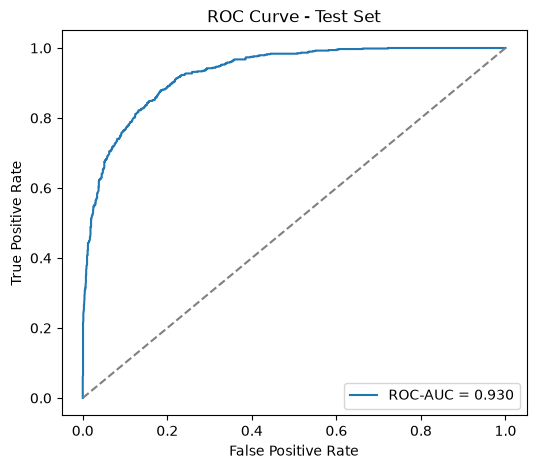

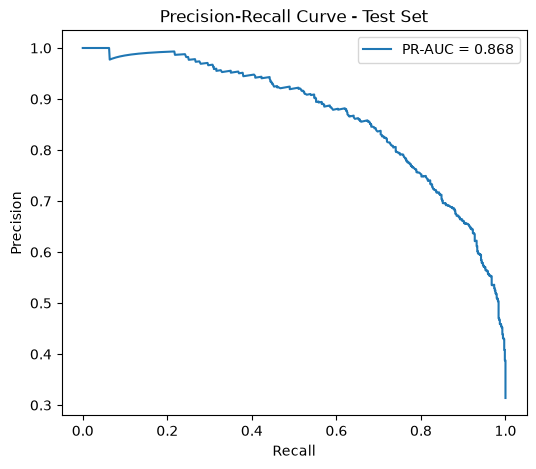

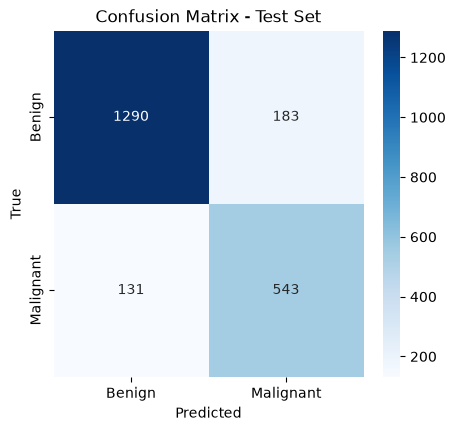

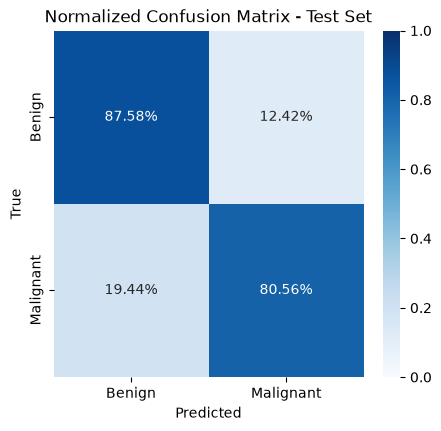

In [16]:
fpr, tpr, _ = roc_curve(test_labels, test_probs)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"ROC-AUC = {metrics['roc_auc']:.3f}")
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve - Test Set"); ax.legend()
fig.savefig(ROC_PR_DIR / "roc_curve.png", bbox_inches="tight", dpi=150)
plt.show()

precision_vals, recall_vals, _ = precision_recall_curve(test_labels, test_probs)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall_vals, precision_vals, label=f"PR-AUC = {metrics['pr_auc']:.3f}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve - Test Set"); ax.legend()
fig.savefig(ROC_PR_DIR / "precision_recall_curve.png", bbox_inches="tight", dpi=150)
plt.show()

cm = confusion_matrix(test_labels, test_preds)
fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Benign", "Malignant"],
            yticklabels=["Benign", "Malignant"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion Matrix - Test Set")
fig.savefig(CONFUSION_MATRICES_DIR / "confusion_matrix.png", bbox_inches="tight", dpi=150)
plt.show()

cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(cm_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=["Benign", "Malignant"],
            yticklabels=["Benign", "Malignant"], ax=ax, vmin=0, vmax=1)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Normalized Confusion Matrix - Test Set")
fig.savefig(CONFUSION_MATRICES_DIR / "normalized_confusion_matrix.png", bbox_inches="tight", dpi=150)
plt.show()


## 17. Predictions Output (Soft Voting Ensemble Contract)

Required schema: `image_id, true_label, predicted_label, probability_benign, probability_malignant`.
Before saving, this is explicitly verified and aligned by `image_id` - never assumed from
DataLoader/iteration order - so it is directly mergeable with the other baseline notebooks'
`predictions.csv` for the future ensemble, with no manual preprocessing needed:

1. Required columns are present.
2. `image_id` is unique (no duplicate predictions).
3. The set of predicted `image_id` values matches `test_df["image_id"]` exactly (no dropped or
   extra rows).
4. Rows are re-aligned onto `test_df`'s `image_id` order via an explicit merge, then sorted by
   `image_id`.

Any mismatch raises `RuntimeError` and stops execution rather than silently saving a
misaligned file.

In [17]:
def finalize_and_save_predictions(predictions_df: pd.DataFrame, test_df: pd.DataFrame, output_path: Path) -> pd.DataFrame:
    required_columns = {"image_id", "true_label", "predicted_label", "probability_benign", "probability_malignant"}
    missing_columns = required_columns - set(predictions_df.columns)
    if missing_columns:
        raise RuntimeError(f"predictions.csv is missing required column(s): {missing_columns}")

    if predictions_df["image_id"].duplicated().any():
        dup_ids = predictions_df.loc[predictions_df["image_id"].duplicated(), "image_id"].tolist()
        raise RuntimeError(f"Duplicate image_id value(s) found in predictions: {dup_ids}")

    predicted_ids = set(predictions_df["image_id"])
    expected_ids = set(test_df["image_id"])
    if predicted_ids != expected_ids:
        missing = expected_ids - predicted_ids
        extra = predicted_ids - expected_ids
        raise RuntimeError(
            f"Predictions do not correspond exactly to the test metadata. "
            f"Missing {len(missing)} (e.g. {list(missing)[:5]}), extra {len(extra)} (e.g. {list(extra)[:5]})."
        )

    # Align explicitly by image_id (never rely on row/iteration order), then sort.
    aligned = test_df[["image_id"]].merge(predictions_df, on="image_id", how="left", validate="one_to_one")
    aligned = aligned.sort_values("image_id").reset_index(drop=True)

    aligned.to_csv(output_path, index=False)
    logger.info("Saved predictions.csv (%d rows, verified + aligned + sorted by image_id) to %s", len(aligned), output_path)
    return aligned


predictions_df = pd.DataFrame({
    "image_id": test_ids,
    "true_label": test_labels.astype(int),
    "predicted_label": test_preds.astype(int),
    "probability_benign": (1 - test_probs).astype(float),
    "probability_malignant": test_probs.astype(float),
})
predictions_df = finalize_and_save_predictions(predictions_df, test_df, PREDICTIONS_DIR / "predictions.csv")

# Also save calibrated validation-set predictions with the same schema. The Soft Voting Ensemble
# notebook needs these (not just test predictions) to choose its own F1-optimal threshold on a
# validation set - never on test - exactly like this notebook does above.
val_preds = (val_probs >= best_threshold).astype(int)
val_predictions_df = pd.DataFrame({
    "image_id": val_ids,
    "true_label": val_labels.astype(int),
    "predicted_label": val_preds.astype(int),
    "probability_benign": (1 - val_probs).astype(float),
    "probability_malignant": val_probs.astype(float),
})
val_predictions_df = finalize_and_save_predictions(val_predictions_df, val_df, PREDICTIONS_DIR / "val_predictions.csv")

predictions_df.head()


2026-07-22 20:13:25,114 | INFO | Saved predictions.csv (2147 rows, verified + aligned + sorted by image_id) to D:\SkinCancer_Project\outputs\binary\Binary_DINOv2_Baseline_V2\predictions\predictions.csv
2026-07-22 20:13:25,123 | INFO | Saved predictions.csv (2147 rows, verified + aligned + sorted by image_id) to D:\SkinCancer_Project\outputs\binary\Binary_DINOv2_Baseline_V2\predictions\val_predictions.csv


,image_id,true_label,predicted_label,probability_benign,probability_malignant
0,ISIC_0000022,1,0,0.744452,0.255548
1,ISIC_0000030,1,1,0.101007,0.898993
2,ISIC_0000142,1,1,0.319577,0.680423
3,ISIC_0000147,1,1,0.061743,0.938257
4,ISIC_0000153,1,0,0.710252,0.289748


## 18. Error Analysis

Splits test predictions into True Positive / True Negative / False Positive / False Negative.
For each category: a CSV, a sample image grid, and summary statistics.

In [18]:
def categorize(row) -> str:
    if row["true_label"] == 1 and row["predicted_label"] == 1:
        return "TP"
    if row["true_label"] == 0 and row["predicted_label"] == 0:
        return "TN"
    if row["true_label"] == 0 and row["predicted_label"] == 1:
        return "FP"
    return "FN"


predictions_df["category"] = predictions_df.apply(categorize, axis=1)
path_by_id = dict(zip(test_df["image_id"], test_df["image_path"]))

CATEGORY_GRID_FILENAMES = {
    "TP": "true_positive_grid.png", "TN": "true_negative_grid.png",
    "FP": "false_positive_grid.png", "FN": "false_negative_grid.png",
}

category_stats = {}
for category in ["TP", "TN", "FP", "FN"]:
    subset = predictions_df[predictions_df["category"] == category]
    subset.to_csv(ERROR_ANALYSIS_DIR / f"{category}.csv", index=False)  # CSVs: top-level error_analysis/

    category_stats[category] = {
        "count": int(len(subset)),
        "mean_probability_malignant": float(subset["probability_malignant"].mean()) if len(subset) else None,
    }

    sample = subset.head(16)
    if len(sample) > 0:
        n_cols = 4
        n_rows = int(np.ceil(len(sample) / n_cols))
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
        axes = np.atleast_1d(axes).flatten()
        for ax, (_, row) in zip(axes, sample.iterrows()):
            img_path = path_by_id.get(row["image_id"])
            try:
                ax.imshow(Image.open(img_path).convert("RGB"))
            except Exception:
                pass
            ax.set_title(f"{row['image_id']}\np(mal)={row['probability_malignant']:.2f}", fontsize=8)
            ax.axis("off")
        for ax in axes[len(sample):]:
            ax.axis("off")
        fig.suptitle(f"{category} - sample of {len(sample)} (of {len(subset)} total)")
        fig.tight_layout()
        # Grids: plots/error_analysis/, with the required descriptive filenames.
        fig.savefig(PLOTS_ERROR_ANALYSIS_DIR / CATEGORY_GRID_FILENAMES[category], bbox_inches="tight", dpi=150)
        plt.close(fig)

with open(ERROR_ANALYSIS_DIR / "error_analysis_stats.json", "w") as f:
    json.dump(category_stats, f, indent=2)

logger.info("Error analysis category counts: %s", {k: v["count"] for k, v in category_stats.items()})
category_stats


2026-07-22 20:13:45,519 | INFO | Error analysis category counts: {'TP': 543, 'TN': 1290, 'FP': 183, 'FN': 131}


{'TP': {'count': 543, 'mean_probability_malignant': 0.7928189984699988},
 'TN': {'count': 1290, 'mean_probability_malignant': 0.07232382432777412},
 'FP': {'count': 183, 'mean_probability_malignant': 0.6125028831327399},
 'FN': {'count': 131, 'mean_probability_malignant': 0.20807041572338925}}

## 19. Run Summary

Writes `metrics_summary.json` (full run summary - matches the DenseNet121 V2 notebook's shape)
and a separate `run_config.json` (just the fully-resolved `CONFIG`, including the backbone's
official values resolved in Section 9) at the top level of `OUTPUT_DIR`.

In [19]:
metrics_summary = {
    "experiment_name": "Binary_DINOv2_Baseline_V2",
    "backbone": "DINOv2 (ViT-B/14)",
    "run_timestamp": RUN_TIMESTAMP,
    "best_epoch": best_state["epoch"],
    "best_val_auc": best_state["val_auc"],
    "best_threshold": best_threshold,
    "used_tta": CONFIG["use_tta"],
    "test_metrics": metrics,
    "outputs_dir": str(OUTPUT_DIR),
}
with open(OUTPUT_DIR / "metrics_summary.json", "w") as f:
    json.dump(metrics_summary, f, indent=2, default=str)

config_to_save = {k: (str(v) if isinstance(v, Path) else v) for k, v in CONFIG.items()}
with open(OUTPUT_DIR / "run_config.json", "w") as f:
    json.dump(config_to_save, f, indent=2, default=str)

logger.info("=== %s finished. Outputs saved to %s ===", "Binary_DINOv2_Baseline_V2", OUTPUT_DIR)
metrics_summary


2026-07-22 20:13:45,532 | INFO | === Binary_DINOv2_Baseline_V2 finished. Outputs saved to D:\SkinCancer_Project\outputs\binary\Binary_DINOv2_Baseline_V2 ===


{'experiment_name': 'Binary_DINOv2_Baseline_V2',
 'backbone': 'DINOv2 (ViT-B/14)',
 'run_timestamp': '20260722_181526',
 'best_epoch': 14,
 'best_val_auc': 0.9240490442559591,
 'best_threshold': 0.4049999999999999,
 'used_tta': True,
 'test_metrics': {'accuracy': 0.8537494177922683,
  'precision': 0.7479338842975206,
  'recall': 0.8056379821958457,
  'f1_score': 0.7757142857142857,
  'roc_auc': 0.9296058025668763,
  'pr_auc': 0.8679629794412331,
  'mcc': 0.6684504254003351,
  'balanced_accuracy': 0.8407008648250105,
  'sensitivity': np.float64(0.8056379821958457),
  'specificity': np.float64(0.8757637474541752),
  'threshold_used': 0.4049999999999999},
 'outputs_dir': 'D:\\SkinCancer_Project\\outputs\\binary\\Binary_DINOv2_Baseline_V2'}